# Notebook 05 — Model Validation

**Enterprise Credit Risk Modeling & Validation Framework**

**Inputs:** `data/processed/` (train / val / oot parquets) · `models/pd/` (trained model artifacts)

**Purpose:** Independent validation of all four PD models using held-out data.
No retraining or tuning occurs here.

**Sections:**
1. OOT Validation — Performance across Val and OOT splits
2. Calibration Assessment — Reliability diagrams + ECE
3. KS Analysis — KS curves and threshold identification
4. ROC Comparison — Val vs OOT side by side
5. Precision-Recall Analysis
6. Lift and Gain Charts
7. Decile Analysis — Rank ordering verification
8. Confusion Matrix — Default + Youden threshold
9. Stability Analysis — PSI (overall + feature-wise)
10. Business Interpretation
11. Validation Summary Table
12. Final Model Recommendation

> **Note on OOT default rate:** The OOT set (2017–2018) has a default rate of ~6.7%,
> artificially low due to the **performance window effect** — recent loans have not yet
> had sufficient time to mature into confirmed defaults. This is expected and must be
> considered when interpreting OOT Brier scores.

In [2]:
import os, sys, subprocess

# Ensure project root working directory
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

# Install fastparquet in the kernel's environment (resolves pandas/pyarrow compat)
subprocess.run([sys.executable, '-m', 'pip', 'install', 'fastparquet', '-q'], capture_output=True)

import pandas as pd
test = pd.read_parquet('data/processed/val.parquet', engine='fastparquet')
print(f'Environment OK: pandas={pd.__version__} | val shape: {test.shape}')
del test

Environment OK: pandas=2.2.3 | val shape: (434406, 51)


In [3]:
import warnings
warnings.filterwarnings('ignore')

import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
if '' not in sys.path:
    sys.path.insert(0, '')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.api as sm

from sklearn.metrics import (
    roc_auc_score, brier_score_loss, roc_curve,
    precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report, log_loss,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import OrdinalEncoder

from src.utils import setup_logging, set_plot_style, save_figure, load_model, PLOT_COLOR, ACCENT_COLOR
from src.preprocessing import apply_woe_encoding

setup_logging()
set_plot_style()

PROCESSED_DIR = 'data/processed'
MODELS_DIR    = 'models/pd'
os.makedirs('reports', exist_ok=True)

PALETTE = {'Logistic Regression': PLOT_COLOR,
           'Random Forest':       ACCENT_COLOR,
           'XGBoost':             '#1a9641',
           'Cox PHM':             '#fdae61'}

print('Setup complete. Working directory:', os.getcwd())

Setup complete. Working directory: [project root]


In [7]:
"""
Load model artifacts saved in cross-version format from PD modeling notebook.
"""
import json
import numpy as np
import pandas as pd
import joblib
import xgboost as xgb

MODELS_DIR = 'models/pd'

def woe_neutral_to_results(neutral_dict):
    '''Reconstruct woe_results from JSON-loaded plain Python dicts.'''
    woe_results = {}
    for feat, meta in neutral_dict.items():
        woe_df = pd.DataFrame(meta['records'])
        for col in ['n_good','n_obs','n_bad']:
            if col in woe_df.columns:
                woe_df[col] = woe_df[col].astype('int32')
        for col in ['bad_rate','pct_good','pct_bad','woe','iv']:
            if col in woe_df.columns:
                woe_df[col] = woe_df[col].astype(float)
        edges = meta.get('bin_edges')
        iv    = float(meta.get('iv', 0.0))
        woe_results[feat] = (woe_df, iv, edges)
    return woe_results

# ── LR: load from JSON ──────────────────────────────────────────────────────
with open(f'{MODELS_DIR}/lr_params.json') as f:
    lr_params_dict = json.load(f)

final_woe_cols = lr_params_dict['final_woe_cols']
lr_features    = lr_params_dict['lr_features']
base_score     = float(lr_params_dict['base_score'])
Factor         = float(lr_params_dict['factor'])
Offset         = float(lr_params_dict['offset'])
woe_results    = woe_neutral_to_results(lr_params_dict['woe_results'])

lr_const      = float(lr_params_dict['const'])
lr_coefs      = np.array(lr_params_dict['coef_values'], dtype=float)
lr_coef_names = lr_params_dict['coef_names']

def predict_lr(X_woe_df):
    X = X_woe_df[lr_coef_names].values.astype(float)
    log_odds = lr_const + X @ lr_coefs
    return 1.0 / (1.0 + np.exp(-log_odds))

# ── RF: load via joblib ─────────────────────────────────────────────────────
rf_art       = joblib.load(f'{MODELS_DIR}/rf_model.joblib')
rf_model     = rf_art['model']
imputer      = rf_art['imputer']
ALL_FEATURES = rf_art['features']

# ── XGBoost: load native format ─────────────────────────────────────────────
xgb_model = xgb.XGBClassifier()
xgb_model.load_model(f'{MODELS_DIR}/xgb_model.json')

# ── Cox: load from JSON coefficients only ──────────────────────────────────
# The full CoxPHFitter has pandas 3.x internal types — not loadable cross-version.
# Coefficient-based prediction gives identical results for AUC / KS / ranking.
with open(f'{MODELS_DIR}/cox_params.json') as f:
    cox_params_dict = json.load(f)
cox_final_woe_cols = cox_params_dict['final_woe_cols']
cox_woe_results    = woe_neutral_to_results(cox_params_dict['woe_results'])
cox_coefs          = np.array(cox_params_dict['coef_values'], dtype=float)
cox_coef_names     = cox_params_dict['coef_names']

def predict_cox_ph(X_woe_df):
    '''Partial hazard = exp(β X). Higher = higher default risk.'''
    X = X_woe_df[cox_coef_names].values.astype(float)
    return np.exp(X @ cox_coefs)

# ── OrdinalEncoder ──────────────────────────────────────────────────────────
enc_art   = joblib.load(f'{MODELS_DIR}/ordinal_encoder.joblib')
enc       = enc_art['encoder']
cat_feats = enc_art['cat_feats']

print('All models loaded successfully.')
print(f'  LR     : {len(lr_coef_names)} WoE features | intercept={lr_const:.4f}')
print(f'  RF     : {rf_model.n_estimators} trees | {len(ALL_FEATURES)} features')
print(f'  XGBoost: {xgb_model.n_estimators} trees')
print(f'  Cox    : {len(cox_coefs)} covariates (coefficient-based; no full model object)')
print(f'  WoE maps: {len(woe_results)} features | Cat encoding: {len(cat_feats)} features')

All models loaded successfully.
  LR     : 18 WoE features | intercept=1.5580
  RF     : 200 trees | 47 features
  XGBoost: None trees
  Cox    : 18 covariates (coefficient-based; no full model object)
  WoE maps: 21 features | Cat encoding: 7 features


In [8]:
# ── Load validation and OOT splits ────────────────────────────────────────
val = pd.read_parquet(f'{PROCESSED_DIR}/val.parquet', engine='fastparquet')
oot = pd.read_parquet(f'{PROCESSED_DIR}/oot.parquet', engine='fastparquet')

# Also load training split (needed for PSI baseline)
train = pd.read_parquet(f'{PROCESSED_DIR}/train.parquet', engine='fastparquet')

SPECIAL_COLS = ['issue_d', 'recovery_rate', 'credit_conversion_factor']
TARGET = 'default'

y_val   = val[TARGET].values
y_oot   = oot[TARGET].values
y_train = train[TARGET].values

print(f'Val  : {len(val):,} rows | default rate: {1-y_val.mean():.2%}')
print(f'OOT  : {len(oot):,} rows | default rate: {1-y_oot.mean():.2%} (performance window effect)')
print(f'Train: {len(train):,} rows | default rate: {1-y_train.mean():.2%}')

Val  : 434,406 rows | default rate: 16.76%
OOT  : 938,821 rows | default rate: 6.74% (performance window effect)
Train: 887,411 rows | default rate: 17.44%


In [9]:
# ── Helper: apply WoE encoding ─────────────────────────────────────────────
def make_woe_matrix(df, final_cols, woe_res):
    '''Apply WoE encoding and return only the final model columns.'''
    result = {}
    for col in final_cols:
        feat = col.replace('_woe', '')
        if feat in woe_res:
            woe_df, _, edges = woe_res[feat]
            result[col] = apply_woe_encoding(df, feat, woe_df, bin_edges=edges)
    return pd.DataFrame(result, index=df.index)

# ── Helper: prepare features for RF / XGBoost ─────────────────────────────
def prepare_tree_features(df):
    X = df[ALL_FEATURES].copy()
    X[cat_feats] = enc.transform(X[cat_feats].astype(str))
    if 'mths_since_last_delinq' in X.columns:
        X['mths_since_last_delinq'] = X['mths_since_last_delinq'].fillna(999)
    return X.astype(float)

# ── Generate predictions ───────────────────────────────────────────────────
print('Generating predictions on Val and OOT...')

# Logistic Regression — coefficient-based (no statsmodels object needed)
X_val_woe = make_woe_matrix(val, final_woe_cols, woe_results)
X_oot_woe = make_woe_matrix(oot, final_woe_cols, woe_results)
prob_val_lr = predict_lr(X_val_woe)
prob_oot_lr = predict_lr(X_oot_woe)
print(f'  LR    — Val P(good) mean: {prob_val_lr.mean():.4f} | OOT: {prob_oot_lr.mean():.4f}')

# Random Forest (with imputation)
X_val_rf  = imputer.transform(prepare_tree_features(val))
X_oot_rf  = imputer.transform(prepare_tree_features(oot))
prob_val_rf  = rf_model.predict_proba(X_val_rf)[:, 1]
prob_oot_rf  = rf_model.predict_proba(X_oot_rf)[:, 1]
print(f'  RF    — Val P(good) mean: {prob_val_rf.mean():.4f} | OOT: {prob_oot_rf.mean():.4f}')

# XGBoost
X_val_xgb    = prepare_tree_features(val)
X_oot_xgb    = prepare_tree_features(oot)
prob_val_xgb = xgb_model.predict_proba(X_val_xgb)[:, 1]
prob_oot_xgb = xgb_model.predict_proba(X_oot_xgb)[:, 1]
print(f'  XGB   — Val P(good) mean: {prob_val_xgb.mean():.4f} | OOT: {prob_oot_xgb.mean():.4f}')

# Cox PHM — coefficient-based partial hazard
X_val_cox_woe = make_woe_matrix(val, cox_final_woe_cols, cox_woe_results)
X_oot_cox_woe = make_woe_matrix(oot, cox_final_woe_cols, cox_woe_results)
ph_val = predict_cox_ph(X_val_cox_woe)
ph_oot = predict_cox_ph(X_oot_cox_woe)
# Normalise using Val min/max (consistent reference between splits)
ph_min, ph_max = ph_val.min(), ph_val.max()
prob_val_cox = 1.0 - (ph_val - ph_min) / (ph_max - ph_min + 1e-10)
prob_oot_cox = np.clip(1.0 - (ph_oot - ph_min) / (ph_max - ph_min + 1e-10), 0, 1)
print(f'  Cox   — Val P(good) mean: {prob_val_cox.mean():.4f} | OOT: {prob_oot_cox.mean():.4f}')

# Collect into dicts for looping over all sections
val_probs = {
    'Logistic Regression': prob_val_lr,
    'Random Forest':        prob_val_rf,
    'XGBoost':              prob_val_xgb,
    'Cox PHM':              prob_val_cox,
}
oot_probs = {
    'Logistic Regression': prob_oot_lr,
    'Random Forest':        prob_oot_rf,
    'XGBoost':              prob_oot_xgb,
    'Cox PHM':              prob_oot_cox,
}

print('\nAll predictions generated successfully.')

Generating predictions on Val and OOT...
  LR    — Val P(good) mean: 0.8299 | OOT: 0.8463
  RF    — Val P(good) mean: 0.5561 | OOT: 0.5813
  XGB   — Val P(good) mean: 0.5536 | OOT: 0.5825
  Cox   — Val P(good) mean: 0.7936 | OOT: 0.8099

All predictions generated successfully.


In [10]:
# ── Evaluation helper functions ────────────────────────────────────────────

def compute_metrics(y_true, y_prob):
    auc   = roc_auc_score(y_true, y_prob)
    brier = brier_score_loss(y_true, y_prob)
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    ks    = float(np.max(tpr - fpr))
    gini  = 2 * auc - 1
    ll    = log_loss(y_true, y_prob)
    return {'AUC': round(auc,4), 'KS': round(ks,4), 'Gini': round(gini,4),
            'Brier': round(brier,4), 'LogLoss': round(ll,4),
            'fpr': fpr, 'tpr': tpr, 'thresholds': thr}

def compute_ece(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i+1])
        if mask.sum() > 0:
            ece += (mask.sum() / len(y_true)) * abs(y_true[mask].mean() - y_prob[mask].mean())
    return round(ece, 4)

def youden_threshold(fpr, tpr, thresholds):
    j = tpr - fpr
    idx = np.argmax(j)
    return float(thresholds[idx]), float(j[idx])

def compute_psi(expected, actual, n_bins=10):
    edges = np.percentile(expected, np.linspace(0, 100, n_bins + 1))
    edges[0] -= 1e-6
    edges[-1] += 1e-6
    exp_pct = np.histogram(expected, bins=edges)[0] / len(expected)
    act_pct = np.histogram(actual,   bins=edges)[0] / len(actual)
    exp_pct = np.clip(exp_pct, 1e-6, None)
    act_pct = np.clip(act_pct, 1e-6, None)
    return round(float(np.sum((act_pct - exp_pct) * np.log(act_pct / exp_pct))), 4)

def psi_label(psi):
    if psi < 0.10: return 'Stable'
    if psi < 0.25: return 'Monitor'
    return 'Unstable'

print('Helper functions defined.')

Helper functions defined.


---
## 1. Out-of-Time (OOT) Validation

Evaluate all four models on both the **Validation set (2016)** and the **OOT set (2017–2018)**.

> **Performance window caveat:** OOT default rate is ~6.7% vs Validation ~16.8%.
> Models trained on pre-2016 data see a lower-risk population in OOT partly because
> recent loans haven't matured. This inflates OOT AUC/KS slightly — rank ordering
> is still meaningful but absolute metrics should be compared cautiously.

In [11]:
# Compute full metrics on Val and OOT for all models
val_metrics = {m: compute_metrics(y_val, p) for m, p in val_probs.items()}
oot_metrics = {m: compute_metrics(y_oot, p) for m, p in oot_probs.items()}

rows = []
for model in val_probs:
    vm, om = val_metrics[model], oot_metrics[model]
    def pct_chg(val, oot):
        return f"{(oot - val) / abs(val) * 100:+.1f}%"
    rows.append({
        'Model':       model,
        'Val AUC':     vm['AUC'],    'OOT AUC':     om['AUC'],    'AUC Δ':     pct_chg(vm['AUC'], om['AUC']),
        'Val KS':      vm['KS'],     'OOT KS':      om['KS'],     'KS Δ':      pct_chg(vm['KS'], om['KS']),
        'Val Gini':    vm['Gini'],   'OOT Gini':    om['Gini'],   'Gini Δ':    pct_chg(vm['Gini'], om['Gini']),
        'Val Brier':   vm['Brier'],  'OOT Brier':   om['Brier'],  'Brier Δ':   pct_chg(vm['Brier'], om['Brier']),
    })

oot_comparison = pd.DataFrame(rows).set_index('Model')
oot_comparison.to_csv('artifacts/oot_validation_comparison.csv')

print('=== Val vs OOT Performance Comparison ===')
print(oot_comparison.to_string())
print()
print('Saved: artifacts/oot_validation_comparison.csv')
print()
print('Degradation note:')
for model in val_probs:
    v_auc = val_metrics[model]['AUC']
    o_auc = oot_metrics[model]['AUC']
    deg = (o_auc - v_auc) / v_auc * 100
    status = 'IMPROVED' if deg > 0 else ('Acceptable' if abs(deg) < 5 else 'Monitor')
    print(f'  {model:<25} AUC: {v_auc:.4f} → {o_auc:.4f}  ({deg:+.1f}%)  [{status}]')

=== Val vs OOT Performance Comparison ===
                     Val AUC  OOT AUC  AUC Δ  Val KS  OOT KS   KS Δ  Val Gini  OOT Gini Gini Δ  Val Brier  OOT Brier Brier Δ
Model                                                                                                                       
Logistic Regression   0.6928   0.6983  +0.8%  0.2783  0.2873  +3.2%    0.3855    0.3965  +2.9%     0.1300     0.0704  -45.8%
Random Forest         0.6993   0.7052  +0.8%  0.2877  0.2978  +3.5%    0.3987    0.4104  +2.9%     0.2113     0.1994   -5.6%
XGBoost               0.7074   0.7108  +0.5%  0.3009  0.3061  +1.7%    0.4148    0.4216  +1.6%     0.2136     0.2021   -5.4%
Cox PHM               0.6948   0.6980  +0.5%  0.2821  0.2892  +2.5%    0.3896    0.3961  +1.7%     0.1314     0.0788  -40.0%

Saved: artifacts/oot_validation_comparison.csv

Degradation note:
  Logistic Regression       AUC: 0.6928 → 0.6983  (+0.8%)  [IMPROVED]
  Random Forest             AUC: 0.6993 → 0.7052  (+0.8%)  [IMPROVED]
 

---
## 2. Calibration Assessment

A **well-calibrated** model produces predicted probabilities that match observed frequencies.
If the model predicts 20% default probability for a group, ~20% of that group should actually default.

**Expected Calibration Error (ECE):** weighted mean absolute difference between predicted
confidence and actual accuracy across probability bins. Lower = better calibrated.

2026-07-26 20:20:10 | INFO     | src.utils | Figure saved → reports\05_calibration_curves.png


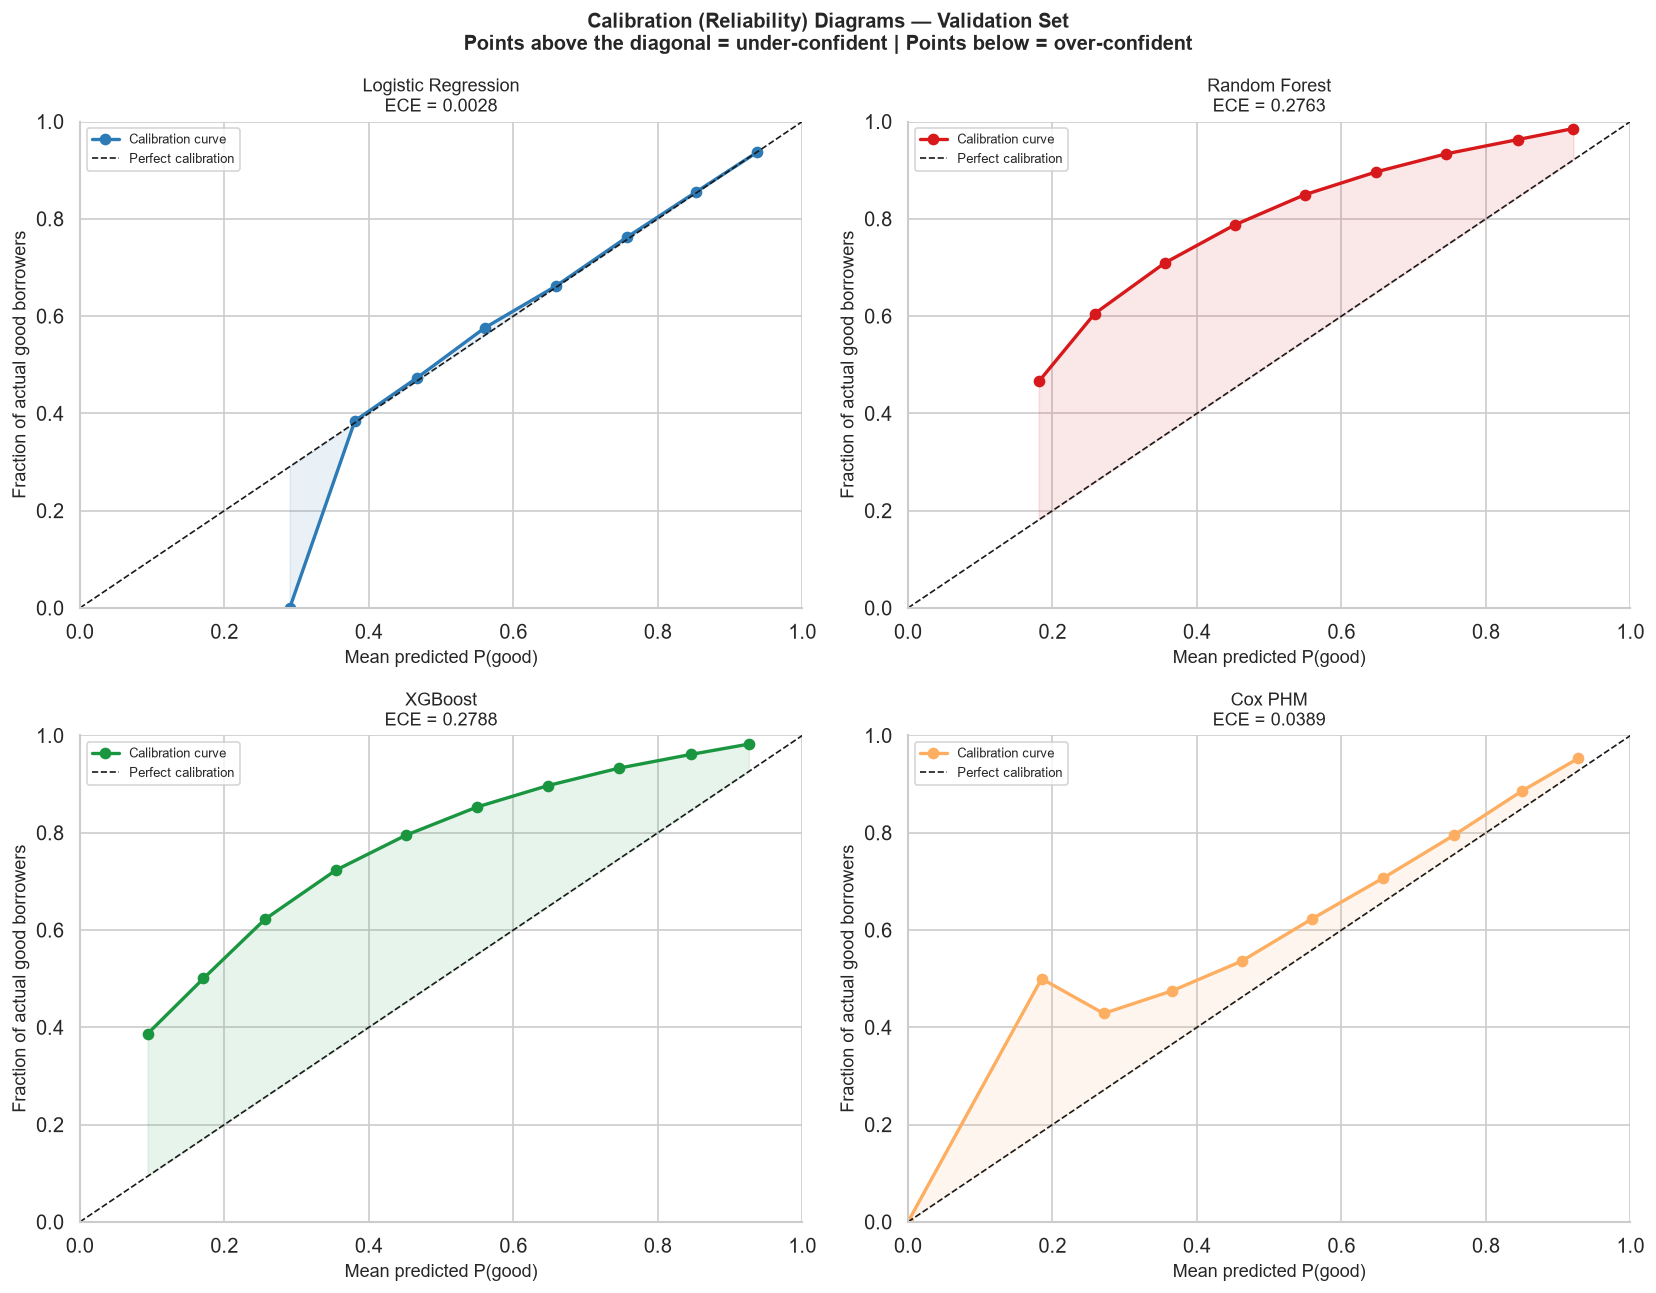

=== Expected Calibration Error (ECE) — Validation Set ===
                     ECE (Val)
Model                         
Logistic Regression     0.0028
Random Forest           0.2763
XGBoost                 0.2788
Cox PHM                 0.0389

Lower ECE = better calibration | LR and Cox produce probabilities inherently; RF/XGB are not calibrated.


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
axes = axes.flatten()
n_cal_bins = 10
ece_table = []

for i, (model_name, prob_val) in enumerate(val_probs.items()):
    # Calibration curve on VAL
    # Note: calibration_curve works with P(positive class).
    # Our positive class is 1=good. We want calibration of P(good) vs actual good rate.
    frac_pos, mean_pred = calibration_curve(y_val, prob_val, n_bins=n_cal_bins, strategy='uniform')
    ece = compute_ece(y_val, prob_val, n_bins=n_cal_bins)
    ece_table.append({'Model': model_name, 'ECE (Val)': ece})

    ax = axes[i]
    ax.plot(mean_pred, frac_pos, marker='o', color=PALETTE[model_name],
            linewidth=2, markersize=6, label='Calibration curve')
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
    ax.fill_between(mean_pred, frac_pos, mean_pred,
                    alpha=0.1, color=PALETTE[model_name])
    ax.set_title(f'{model_name}\nECE = {ece:.4f}', fontsize=11)
    ax.set_xlabel('Mean predicted P(good)')
    ax.set_ylabel('Fraction of actual good borrowers')
    ax.legend(fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

fig.suptitle('Calibration (Reliability) Diagrams — Validation Set\n'
             'Points above the diagonal = under-confident | Points below = over-confident',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_figure(fig, '05_calibration_curves.png')
plt.show()

ece_df = pd.DataFrame(ece_table).set_index('Model')
print('=== Expected Calibration Error (ECE) — Validation Set ===')
print(ece_df.to_string())
print('\nLower ECE = better calibration | LR and Cox produce probabilities inherently; '
      'RF/XGB are not calibrated.')

---
## 3. KS Analysis

The **KS statistic** measures the maximum separation between the cumulative distribution
functions of scores for good and bad borrowers. The KS curve shows this graphically.

The score threshold where KS is maximum is the single best cut-point for separating
good from bad borrowers under the model.

2026-07-26 20:20:29 | INFO     | src.utils | Figure saved → reports\05_ks_curves.png


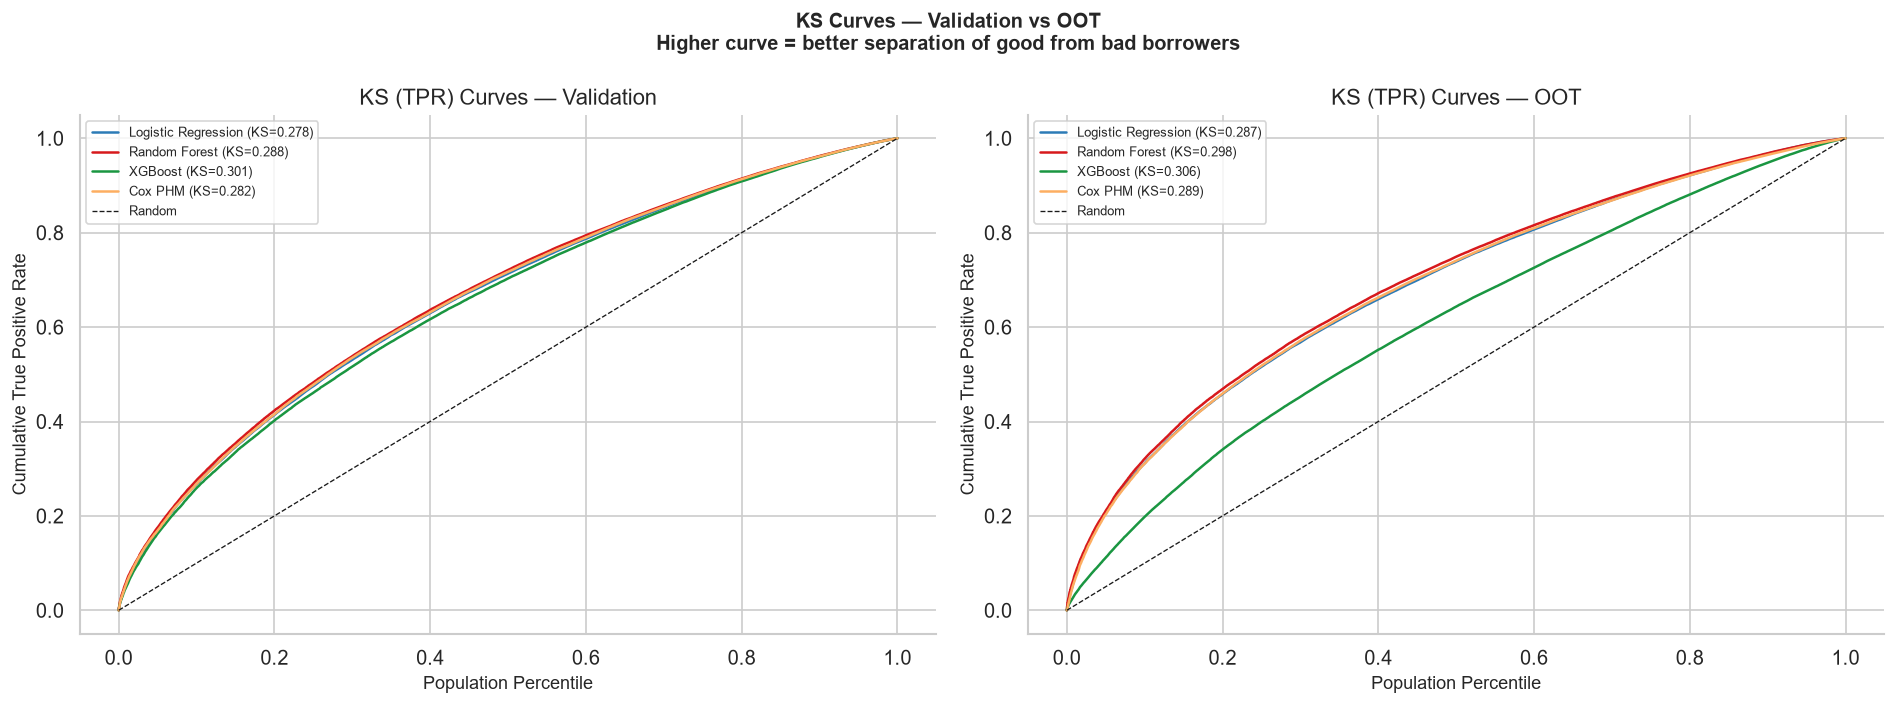

=== KS Summary ===
                         KS            Threshold           
Split                   OOT Validation       OOT Validation
Model                                                      
Cox PHM              0.2892     0.2821    0.8069     0.7957
Logistic Regression  0.2873     0.2783    0.8463     0.8313
Random Forest        0.2978     0.2877    0.5445     0.5091
XGBoost              0.3061     0.3009    0.5505     0.5036


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ks_summary = []
for split_name, (y_true, probs_dict) in [('Validation', (y_val, val_probs)),
                                          ('OOT',        (y_oot, oot_probs))]:
    ax_idx = 0 if split_name == 'Validation' else 1
    ax = axes[ax_idx]

    for model_name, y_prob in probs_dict.items():
        fpr, tpr, thr = roc_curve(y_true, y_prob)
        ks_vals = tpr - fpr
        ks_idx  = np.argmax(ks_vals)
        ks_stat = ks_vals[ks_idx]
        ks_thr  = thr[ks_idx]

        # KS curve = cumulative distribution of good and bad separately
        pct_pop = fpr  # cumulative % of bad borrowers (sorted by score desc)
        ax.plot(np.linspace(0, 1, len(tpr)), tpr,
                color=PALETTE[model_name], linestyle='-', linewidth=1.5,
                label=f'{model_name} (KS={ks_stat:.3f})')

        if split_name == 'Validation':
            ks_summary.append({
                'Model': model_name, 'Split': split_name,
                'KS': round(ks_stat, 4), 'Threshold': round(ks_thr, 4)
            })
        else:
            ks_summary.append({
                'Model': model_name, 'Split': split_name,
                'KS': round(ks_stat, 4), 'Threshold': round(ks_thr, 4)
            })

    ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random')
    ax.set_title(f'KS (TPR) Curves — {split_name}')
    ax.set_xlabel('Population Percentile')
    ax.set_ylabel('Cumulative True Positive Rate')
    ax.legend(fontsize=8)

fig.suptitle('KS Curves — Validation vs OOT\n'
             'Higher curve = better separation of good from bad borrowers',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_figure(fig, '05_ks_curves.png')
plt.show()

ks_df = pd.DataFrame(ks_summary)
ks_pivot = ks_df.pivot(index='Model', columns='Split', values=['KS', 'Threshold'])
print('=== KS Summary ===')
print(ks_pivot.to_string())

---
## 4. ROC Comparison — Validation vs OOT

2026-07-26 20:20:50 | INFO     | src.utils | Figure saved → reports\05_roc_comparison.png


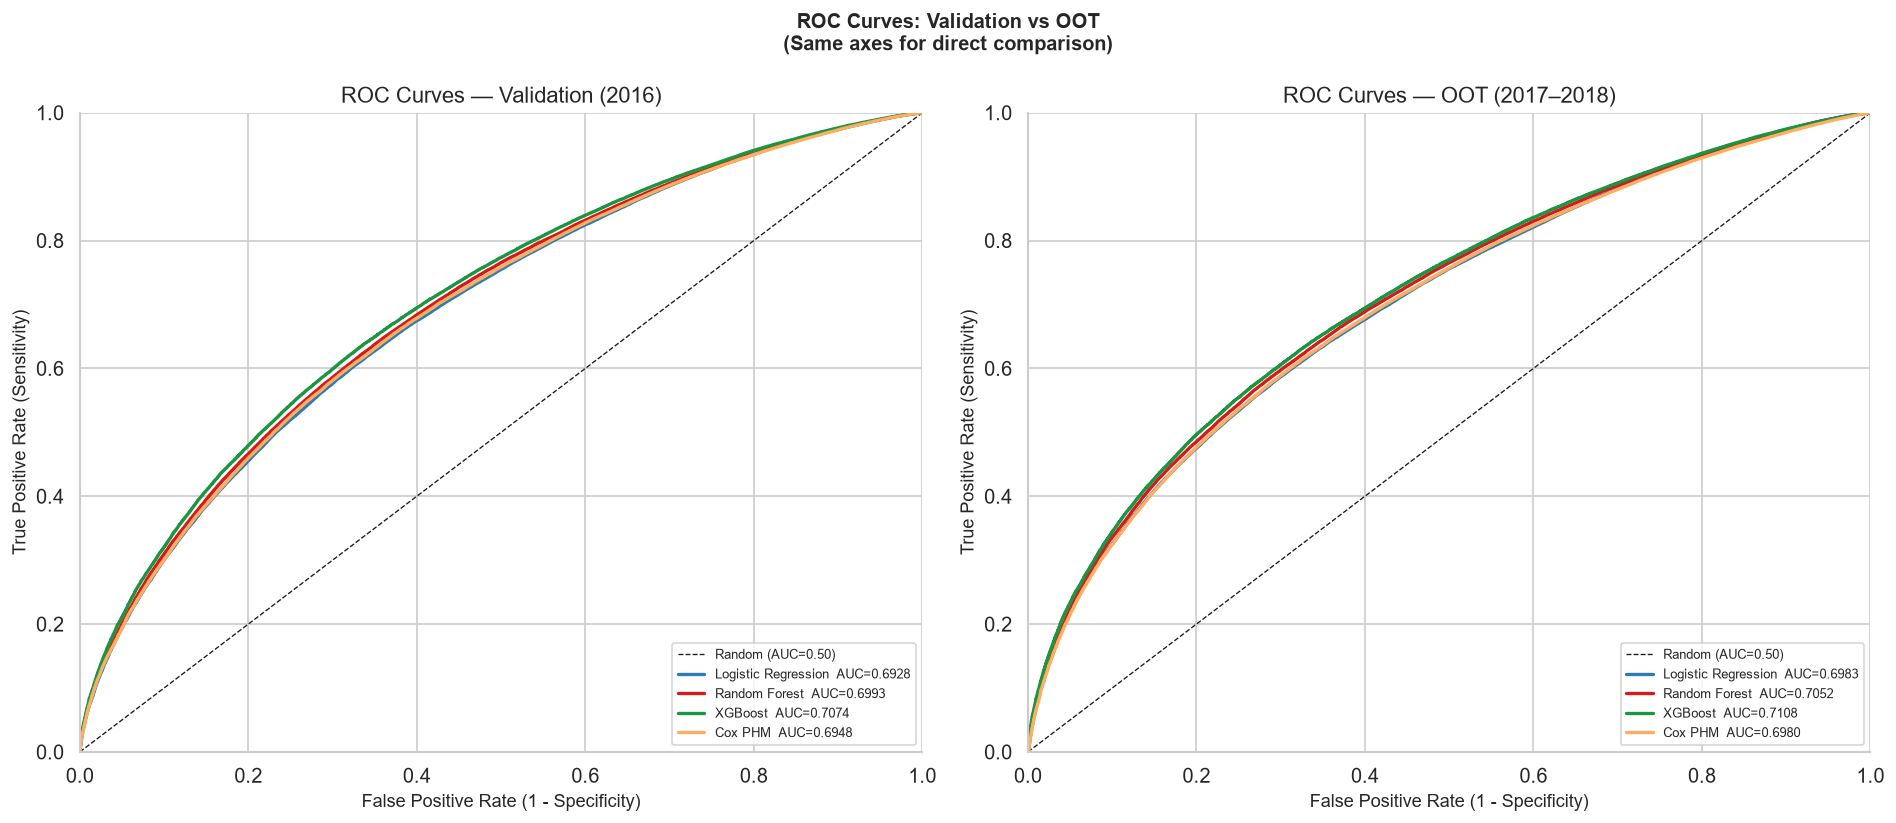

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax_idx, (split_name, y_true, probs_dict) in enumerate([
    ('Validation (2016)', y_val, val_probs),
    ('OOT (2017–2018)',   y_oot, oot_probs),
]):
    ax = axes[ax_idx]
    ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8, label='Random (AUC=0.50)')
    for model_name, y_prob in probs_dict.items():
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc = roc_auc_score(y_true, y_prob)
        ax.plot(fpr, tpr, color=PALETTE[model_name], linewidth=2,
                label=f'{model_name}  AUC={auc:.4f}')
    ax.set_xlabel('False Positive Rate (1 - Specificity)')
    ax.set_ylabel('True Positive Rate (Sensitivity)')
    ax.set_title(f'ROC Curves — {split_name}')
    ax.legend(loc='lower right', fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

fig.suptitle('ROC Curves: Validation vs OOT\n(Same axes for direct comparison)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_figure(fig, '05_roc_comparison.png')
plt.show()

---
## 5. Precision-Recall Analysis

Under class imbalance (~17% default rate), Precision-Recall curves are more informative
than ROC curves for evaluating how effectively models identify the minority class (defaulters).

**Average Precision (AP):** area under the PR curve. Higher = better recall at any precision level.

2026-07-26 20:21:09 | INFO     | src.utils | Figure saved → reports\05_precision_recall.png


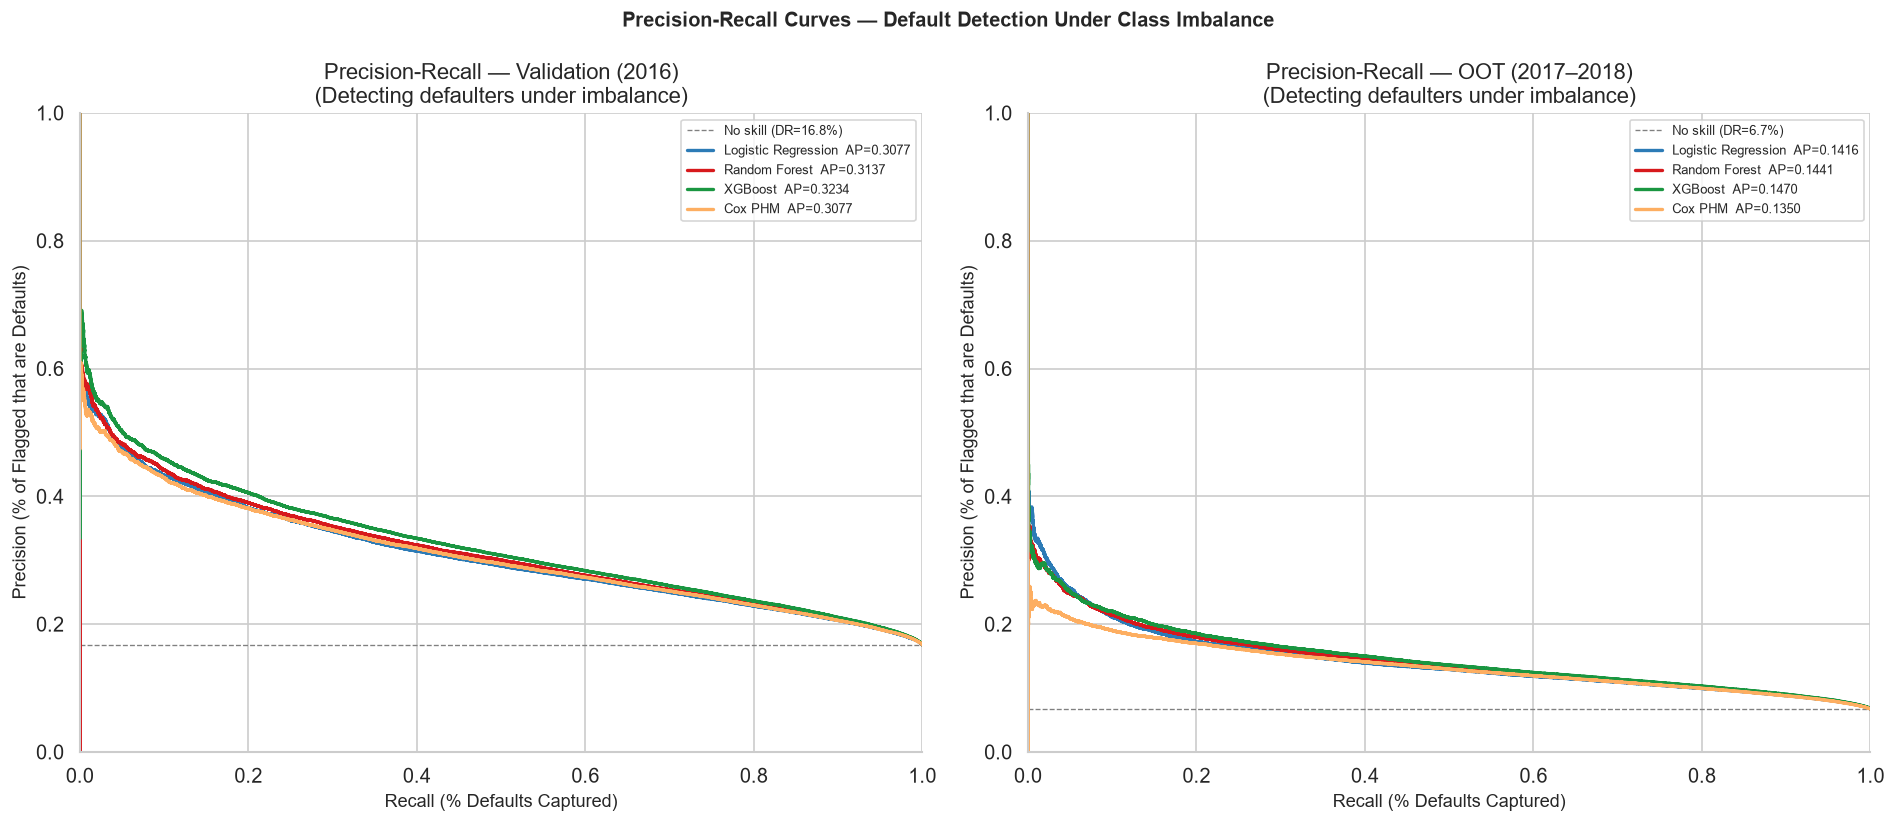

=== Average Precision (AP) — Default Detection ===
                     Val AP  OOT AP
Model                              
Logistic Regression  0.3077  0.1416
Random Forest        0.3137  0.1441
XGBoost              0.3234  0.1470
Cox PHM              0.3077  0.1350

Higher AP = better at capturing defaulters at any recall threshold.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
ap_table = []

for ax_idx, (split_name, y_true, probs_dict) in enumerate([
    ('Validation (2016)', y_val, val_probs),
    ('OOT (2017–2018)',   y_oot, oot_probs),
]):
    ax = axes[ax_idx]
    baseline = 1 - y_true.mean()  # default rate = fraction of bad (class=0)
    ax.axhline(baseline, color='gray', linestyle='--', linewidth=0.8,
               label=f'No skill (DR={baseline:.1%})')

    for model_name, y_prob in probs_dict.items():
        # PR curve for detecting BAD borrowers (class=0 = default)
        # We need P(default) = 1 - P(good) to compute PR for the default class
        prob_default = 1 - y_prob
        y_binary_default = (y_true == 0).astype(int)  # 1=bad, 0=good
        precision, recall, _ = precision_recall_curve(y_binary_default, prob_default)
        ap = average_precision_score(y_binary_default, prob_default)
        ax.plot(recall, precision, color=PALETTE[model_name], linewidth=2,
                label=f'{model_name}  AP={ap:.4f}')
        if split_name == 'Validation (2016)':
            ap_table.append({'Model': model_name, 'Val AP': round(ap, 4)})
        else:
            for row in ap_table:
                if row['Model'] == model_name:
                    row['OOT AP'] = round(ap, 4)

    ax.set_xlabel('Recall (% Defaults Captured)')
    ax.set_ylabel('Precision (% of Flagged that are Defaults)')
    ax.set_title(f'Precision-Recall — {split_name}\n(Detecting defaulters under imbalance)')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

fig.suptitle('Precision-Recall Curves — Default Detection Under Class Imbalance',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_figure(fig, '05_precision_recall.png')
plt.show()

print('=== Average Precision (AP) — Default Detection ===')
print(pd.DataFrame(ap_table).set_index('Model').to_string())
print('\nHigher AP = better at capturing defaulters at any recall threshold.')

---
## 6. Lift and Gain Charts

**Cumulative Gain chart:** Shows what % of defaults are captured if the model is used to
target the top X% of the population (sorted by predicted default risk).

**Lift:** Ratio of defaults captured in the top X% vs random selection.
A lift of 3.0 at 20% means the top 20% of the model's high-risk population captures
3× more defaults than randomly selecting 20%.

Both charts use **Validation set only** (OOT has performance window effect).

2026-07-26 20:21:26 | INFO     | src.utils | Figure saved → reports\05_lift_gain_charts.png


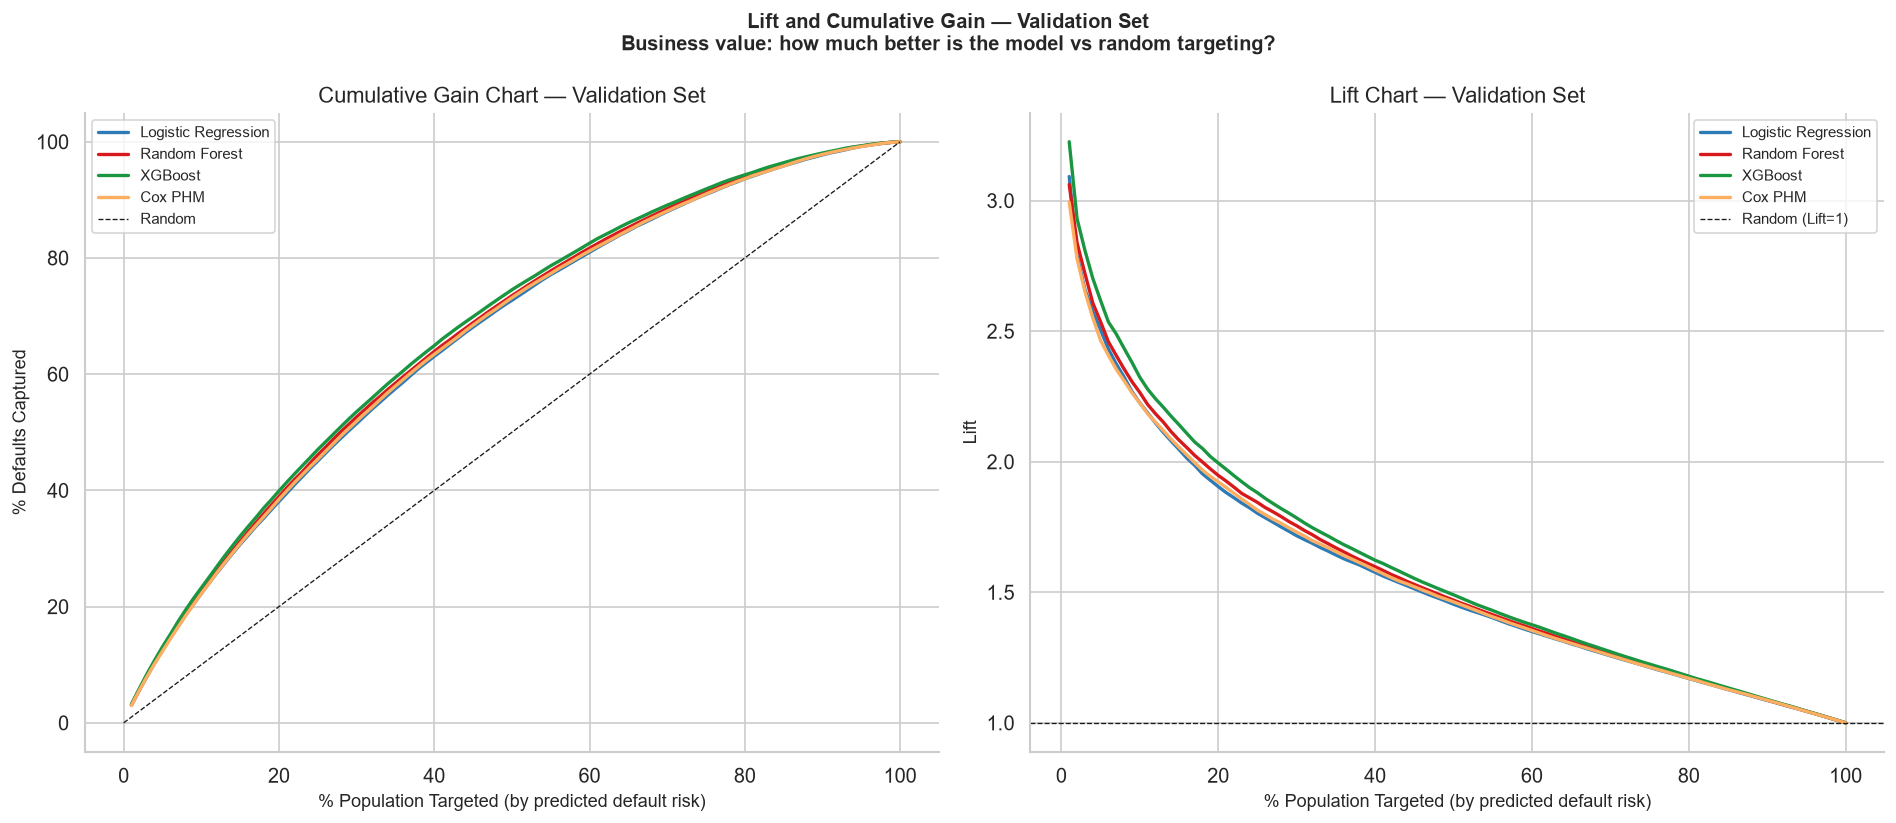

=== Lift at Key Percentiles (Validation Set) ===
  Logistic Regression       {'Lift@10%': np.float64(2.23), 'Lift@20%': np.float64(1.9), 'Lift@30%': np.float64(1.72), 'Lift@50%': np.float64(1.45)}
  Random Forest             {'Lift@10%': np.float64(2.27), 'Lift@20%': np.float64(1.95), 'Lift@30%': np.float64(1.75), 'Lift@50%': np.float64(1.47)}
  XGBoost                   {'Lift@10%': np.float64(2.32), 'Lift@20%': np.float64(2.0), 'Lift@30%': np.float64(1.78), 'Lift@50%': np.float64(1.49)}
  Cox PHM                   {'Lift@10%': np.float64(2.22), 'Lift@20%': np.float64(1.92), 'Lift@30%': np.float64(1.73), 'Lift@50%': np.float64(1.46)}


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

n_points = 100
pct_pop  = np.linspace(0.01, 1.0, n_points)
overall_dr = 1 - y_val.mean()  # overall default rate in val

for model_name, y_prob in val_probs.items():
    prob_default = 1 - y_prob
    y_is_bad = (y_val == 0).astype(int)

    # Sort by predicted default probability descending
    sort_idx = np.argsort(prob_default)[::-1]
    sorted_bad = y_is_bad[sort_idx]
    n_total_bad = sorted_bad.sum()

    cum_bad_pct  = []
    lift_vals    = []
    for pct in pct_pop:
        n_selected = int(pct * len(sorted_bad))
        n_bad_cap  = sorted_bad[:n_selected].sum()
        cum_bad_pct.append(n_bad_cap / n_total_bad)
        dr_in_seg = n_bad_cap / n_selected if n_selected > 0 else 0
        lift_vals.append(dr_in_seg / overall_dr)

    axes[0].plot(pct_pop * 100, [v * 100 for v in cum_bad_pct],
                 color=PALETTE[model_name], linewidth=2, label=model_name)
    axes[1].plot(pct_pop * 100, lift_vals,
                 color=PALETTE[model_name], linewidth=2, label=model_name)

# Random baseline
axes[0].plot([0, 100], [0, 100], 'k--', linewidth=0.8, label='Random')
axes[1].axhline(1.0, color='k', linestyle='--', linewidth=0.8, label='Random (Lift=1)')

axes[0].set_xlabel('% Population Targeted (by predicted default risk)')
axes[0].set_ylabel('% Defaults Captured')
axes[0].set_title('Cumulative Gain Chart — Validation Set')
axes[0].legend(fontsize=9)

axes[1].set_xlabel('% Population Targeted (by predicted default risk)')
axes[1].set_ylabel('Lift')
axes[1].set_title('Lift Chart — Validation Set')
axes[1].legend(fontsize=9)

fig.suptitle('Lift and Cumulative Gain — Validation Set\n'
             'Business value: how much better is the model vs random targeting?',
             fontsize=12, fontweight='bold')
plt.tight_layout()
save_figure(fig, '05_lift_gain_charts.png')
plt.show()

# Print lift at key deciles
print('=== Lift at Key Percentiles (Validation Set) ===')
for model_name, y_prob in val_probs.items():
    prob_default = 1 - y_prob
    y_is_bad = (y_val == 0).astype(int)
    sort_idx = np.argsort(prob_default)[::-1]
    sorted_bad = y_is_bad[sort_idx]
    n_bad = sorted_bad.sum()
    lifts = {}
    for pct in [0.10, 0.20, 0.30, 0.50]:
        n_sel = int(pct * len(sorted_bad))
        dr_seg = sorted_bad[:n_sel].sum() / n_sel
        lifts[f'Lift@{int(pct*100)}%'] = round(dr_seg / overall_dr, 2)
    print(f'  {model_name:<25}', lifts)

---
## 7. Decile Analysis

Borrowers are divided into 10 equal groups (deciles) by predicted score.
The default rate should **decrease monotonically** from Decile 1 (highest risk) to Decile 10 (lowest risk).

Monotonicity confirms the model's rank-ordering ability and validates the scorecard for operational use.

In [17]:
def decile_table(y_true, y_prob, split_name):
    '''Generate decile analysis table sorted by default risk (decile 1 = highest risk).'''
    df_d = pd.DataFrame({'prob_good': y_prob, 'default': y_true})
    df_d['decile'] = pd.qcut(df_d['prob_good'], q=10, labels=range(10, 0, -1))
    df_d['decile'] = df_d['decile'].astype(int)
    grp = df_d.groupby('decile').agg(
        N          = ('default', 'count'),
        N_Good     = ('default', 'sum'),
        N_Bad      = ('default', lambda x: (x==0).sum()),
        Bad_Rate   = ('default', lambda x: round(1 - x.mean(), 4)),
        Avg_PGood  = ('prob_good', lambda x: round(x.mean(), 4)),
    ).sort_index(ascending=False)
    grp['Cum_Bad']   = grp['N_Bad'].cumsum()
    grp['Cum_Bad%']  = (grp['Cum_Bad'] / grp['N_Bad'].sum() * 100).round(1)
    total_dr = 1 - y_true.mean()
    grp['Lift']      = (grp['Bad_Rate'] / total_dr).round(2)
    grp.index.name   = 'Decile'
    return grp

# Show decile table for XGBoost (best AUC model) on Val and OOT
print('=== Decile Analysis — XGBoost | Validation Set ===')
dec_val_xgb = decile_table(y_val, prob_val_xgb, 'Validation')
print(dec_val_xgb.to_string())

print()
print('=== Decile Analysis — XGBoost | OOT Set ===')
dec_oot_xgb = decile_table(y_oot, prob_oot_xgb, 'OOT')
print(dec_oot_xgb.to_string())
print('\n[OOT: low absolute default rates due to performance window effect —')
print(' check rank ordering (monotonic decrease), not absolute levels]')

=== Decile Analysis — XGBoost | Validation Set ===
            N  N_Good  N_Bad  Bad_Rate  Avg_PGood  Cum_Bad  Cum_Bad%  Lift
Decile                                                                    
10      43441   26526  16915    0.3894     0.2483    16915      23.2  2.32
9       43441   31307  12134    0.2793     0.3526    29049      39.9  1.67
8       43440   33511   9929    0.2286     0.4171    38978      53.5  1.36
7       43441   35166   8275    0.1905     0.4718    47253      64.9  1.14
6       43440   36447   6993    0.1610     0.5233    54246      74.5  0.96
5       43441   37599   5842    0.1345     0.5748    60088      82.5  0.80
4       43440   38671   4769    0.1098     0.6285    64857      89.1  0.66
3       43441   39646   3795    0.0874     0.6880    68652      94.3  0.52
2       43440   40704   2736    0.0630     0.7613    71388      98.1  0.38
1       43441   42031   1410    0.0325     0.8705    72798     100.0  0.19

=== Decile Analysis — XGBoost | OOT Set ===
    

2026-07-26 20:22:02 | INFO     | src.utils | Figure saved → reports\05_decile_default_rates.png


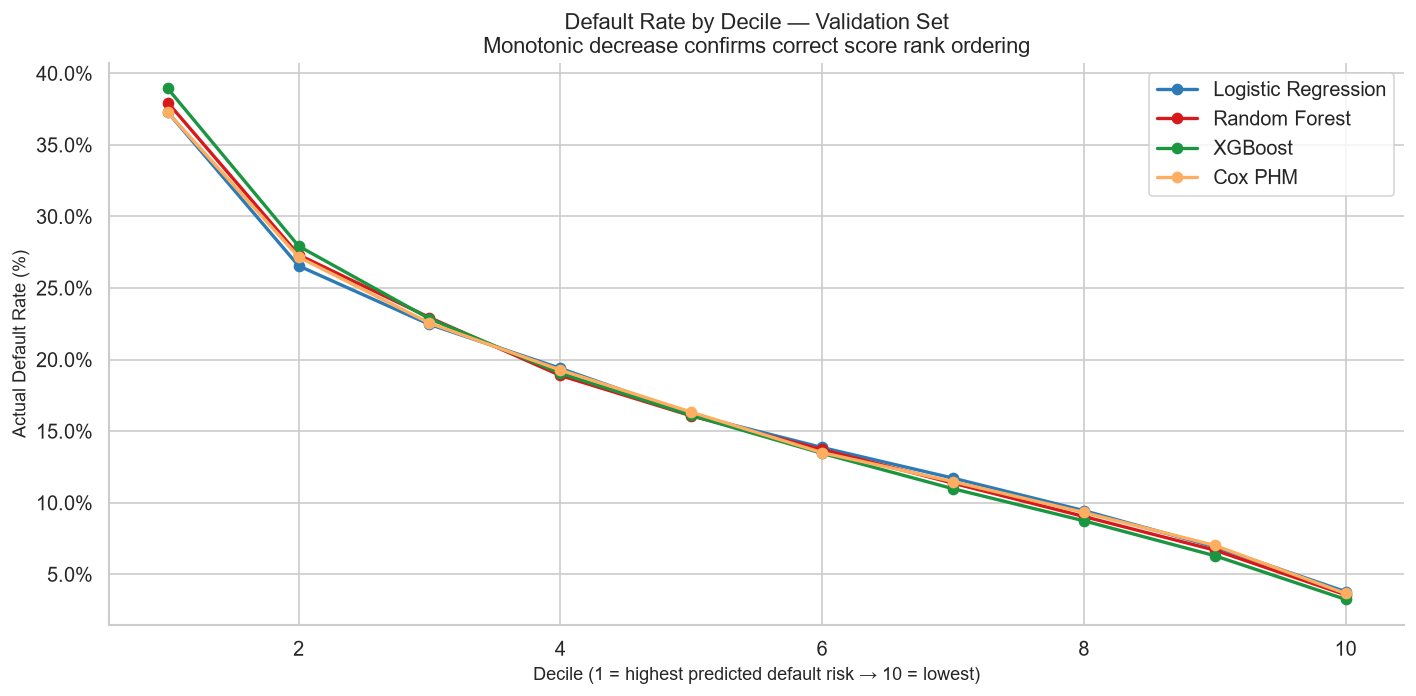

Decile tables saved to artifacts/


In [18]:
# Monotonicity check — plot default rate per decile for all models on Validation
fig, ax = plt.subplots(figsize=(12, 6))
x = range(1, 11)

for model_name, y_prob in val_probs.items():
    dec = decile_table(y_val, y_prob, 'Val')
    bad_rates = dec.sort_index(ascending=False)['Bad_Rate'].values  # decile 1=highest risk
    ax.plot(x, bad_rates * 100, marker='o', linewidth=2,
            color=PALETTE[model_name], label=model_name)
    dec.to_csv(f'artifacts/decile_{model_name.replace(" ", "_").lower()}_val.csv')

ax.set_xlabel('Decile (1 = highest predicted default risk → 10 = lowest)')
ax.set_ylabel('Actual Default Rate (%)')
ax.set_title('Default Rate by Decile — Validation Set\n'
             'Monotonic decrease confirms correct score rank ordering')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.legend()
plt.tight_layout()
save_figure(fig, '05_decile_default_rates.png')
plt.show()
print('Decile tables saved to artifacts/')

---
## 8. Confusion Matrix — Default and Optimal Thresholds

The **default threshold (0.5)** classifies a borrower as bad if P(good) < 0.5.
Given the ~17% default rate, this threshold is far from optimal.

**Youden's J threshold** maximises `sensitivity + specificity - 1`, balancing
the cost of missing a defaulter against the cost of incorrectly rejecting a good borrower.

In [19]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

threshold_summary = []

for model_name, y_prob in val_probs.items():
    fpr, tpr, thr = roc_curve(y_val, y_prob)
    youden_thr, youden_j = youden_threshold(fpr, tpr, thr)

    for thr_name, threshold in [('Default (0.5)', 0.5), (f'Youden (J={youden_j:.3f})', youden_thr)]:
        y_pred = (y_prob >= threshold).astype(int)  # predict GOOD if prob_good >= threshold
        cm = confusion_matrix(y_val, y_pred)
        tn, fp, fn, tp = cm.ravel()
        accuracy    = round((tp + tn) / len(y_val), 4)
        precision   = round(tp / (tp + fp) if (tp + fp) > 0 else 0, 4)
        recall_     = round(tp / (tp + fn) if (tp + fn) > 0 else 0, 4)  # sensitivity for good
        specificity = round(tn / (tn + fp) if (tn + fp) > 0 else 0, 4)  # sensitivity for bad
        f1          = round(f1_score(y_val, y_pred), 4)
        threshold_summary.append({
            'Model': model_name, 'Threshold': thr_name,
            'Cut-off': round(threshold, 3),
            'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
            'Accuracy': accuracy, 'Precision': precision,
            'Recall(Sens)': recall_, 'Specificity': specificity, 'F1': f1,
        })

thresh_df = pd.DataFrame(threshold_summary)
thresh_df.to_csv('artifacts/confusion_matrix_summary.csv', index=False)

print('=== Confusion Matrix Summary — Validation Set ===')
print(thresh_df[['Model', 'Threshold', 'Cut-off', 'Accuracy', 'Precision',
                  'Recall(Sens)', 'Specificity', 'F1']].to_string(index=False))
print()
print('Saved: artifacts/confusion_matrix_summary.csv')
print()
print('Note: Recall(Sens) = % of GOOD borrowers correctly identified.')
print('      Specificity   = % of BAD  borrowers correctly identified (missed defaults avoided).')

=== Confusion Matrix Summary — Validation Set ===
              Model        Threshold  Cut-off  Accuracy  Precision  Recall(Sens)  Specificity     F1
Logistic Regression    Default (0.5)    0.500    0.8328     0.8345        0.9969       0.0178 0.9085
Logistic Regression Youden (J=0.278)    0.831    0.6170     0.9018        0.6059       0.6724 0.7248
      Random Forest    Default (0.5)    0.500    0.6532     0.8979        0.6582       0.6282 0.7596
      Random Forest Youden (J=0.288)    0.509    0.6404     0.9004        0.6387       0.6491 0.7473
            XGBoost    Default (0.5)    0.500    0.6471     0.9027        0.6457       0.6541 0.7529
            XGBoost Youden (J=0.301)    0.504    0.6428     0.9038        0.6389       0.6620 0.7486
            Cox PHM    Default (0.5)    0.500    0.8317     0.8374        0.9901       0.0448 0.9073
            Cox PHM Youden (J=0.282)    0.796    0.6202     0.9024        0.6096       0.6725 0.7277

Saved: artifacts/confusion_matrix_summar

---
## 9. Stability Analysis — Population Stability Index (PSI)

**PSI** measures how much the distribution of a model output (or feature) has shifted
between the training period and the deployment period.

| PSI | Interpretation |
|-----|----------------|
| < 0.10 | Stable — no significant change |
| 0.10 – 0.25 | Monitor — some population shift |
| > 0.25 | Unstable — model may need revalidation or rebuilding |

**Overall PSI:** computed on the model's predicted score distribution.
**Feature-wise PSI (CSI):** computed on each input feature's distribution.

In [21]:
# ── Overall PSI: predicted score distribution (Train → Val → OOT) ──────────
print('Generating training set predictions for PSI baseline (takes ~1 min)...')

X_train_woe_psi = make_woe_matrix(train, final_woe_cols, woe_results)
prob_train_lr   = predict_lr(X_train_woe_psi)

X_train_tree    = imputer.transform(prepare_tree_features(train))
prob_train_rf   = rf_model.predict_proba(X_train_tree)[:, 1]

X_train_xgb_psi = prepare_tree_features(train)
prob_train_xgb  = xgb_model.predict_proba(X_train_xgb_psi)[:, 1]

X_train_cox_woe = make_woe_matrix(train, cox_final_woe_cols, cox_woe_results)
ph_train        = predict_cox_ph(X_train_cox_woe)
prob_train_cox  = np.clip(1.0 - (ph_train - ph_min) / (ph_max - ph_min + 1e-10), 0, 1)

train_probs = {
    'Logistic Regression': prob_train_lr,
    'Random Forest':        prob_train_rf,
    'XGBoost':              prob_train_xgb,
    'Cox PHM':              prob_train_cox,
}

psi_rows = []
for model_name in val_probs:
    psi_val = compute_psi(train_probs[model_name], val_probs[model_name])
    psi_oot = compute_psi(train_probs[model_name], oot_probs[model_name])
    psi_rows.append({
        'Model':           model_name,
        'PSI (Train→Val)': psi_val, 'PSI Val Status': psi_label(psi_val),
        'PSI (Train→OOT)': psi_oot, 'PSI OOT Status': psi_label(psi_oot),
    })

psi_df = pd.DataFrame(psi_rows).set_index('Model')
psi_df.to_csv('artifacts/psi_overall.csv')

print('=== Overall PSI — Predicted Score Distribution ===')
print(psi_df.to_string())
print()
print('Saved: artifacts/psi_overall.csv')

Generating training set predictions for PSI baseline (takes ~1 min)...
=== Overall PSI — Predicted Score Distribution ===
                     PSI (Train→Val) PSI Val Status  PSI (Train→OOT) PSI OOT Status
Model                                                                              
Logistic Regression           0.0074         Stable           0.0490         Stable
Random Forest                 0.0041         Stable           0.0430         Stable
XGBoost                       0.0032         Stable           0.0407         Stable
Cox PHM                       0.0016         Stable           0.0324         Stable

Saved: artifacts/psi_overall.csv


In [22]:
# ── Feature-wise PSI (Characteristic Stability Index) ─────────────────────
# Compare distribution of each feature between Train and OOT

# Focus on the top 15 features by RF importance (most business-relevant)
rf_importance = pd.Series(rf_model.feature_importances_, index=ALL_FEATURES).sort_values(ascending=False)
top_features  = rf_importance.head(15).index.tolist()

feat_psi_rows = []
for feat in top_features:
    try:
        train_vals = train[feat].dropna().astype(float) if train[feat].dtype != 'object' else None
        oot_vals   = oot[feat].dropna().astype(float) if oot[feat].dtype != 'object' else None
        if train_vals is not None and oot_vals is not None and len(train_vals) > 0 and len(oot_vals) > 0:
            psi_val = compute_psi(train[feat].dropna().astype(float), val[feat].dropna().astype(float))
            psi_oot = compute_psi(train_vals, oot_vals)
            feat_psi_rows.append({
                'Feature':         feat,
                'RF Rank':         rf_importance.rank(ascending=False).astype(int)[feat],
                'PSI (T→Val)':     psi_val,  'Val Status': psi_label(psi_val),
                'PSI (T→OOT)':     psi_oot,  'OOT Status': psi_label(psi_oot),
            })
    except Exception as e:
        feat_psi_rows.append({'Feature': feat, 'PSI (T→OOT)': 'Error', 'OOT Status': str(e)[:30]})

feat_psi_df = pd.DataFrame(feat_psi_rows).sort_values('PSI (T→OOT)', ascending=False)
feat_psi_df.to_csv('artifacts/psi_feature_wise.csv', index=False)

print('=== Feature-wise PSI (Characteristic Stability Index) ===')
print('Train → OOT comparison for top 15 features by RF importance')
print()
print(feat_psi_df.to_string(index=False))
print()
print('Saved: artifacts/psi_feature_wise.csv')

=== Feature-wise PSI (Characteristic Stability Index) ===
Train → OOT comparison for top 15 features by RF importance

             Feature  RF Rank  PSI (T→Val) Val Status  PSI (T→OOT) OOT Status
            int_rate        3       0.0897     Stable       0.1238    Monitor
      fico_range_low        7       0.0011     Stable       0.0666     Stable
     fico_range_high        8       0.0011     Stable       0.0666     Stable
         installment       12       0.0150     Stable       0.0296     Stable
           loan_amnt       13       0.0070     Stable       0.0229     Stable
           revol_bal       15       0.0057     Stable       0.0218     Stable
                 dti        6       0.0060     Stable       0.0141     Stable
          annual_inc        9       0.0081     Stable       0.0136     Stable
         tot_cur_bal       11       0.0014     Stable       0.0109     Stable
     tot_hi_cred_lim       10       0.0038     Stable       0.0104     Stable
mths_since_recent_bc   

2026-07-26 20:24:11 | INFO     | src.utils | Figure saved → reports\05_psi_feature_wise.png


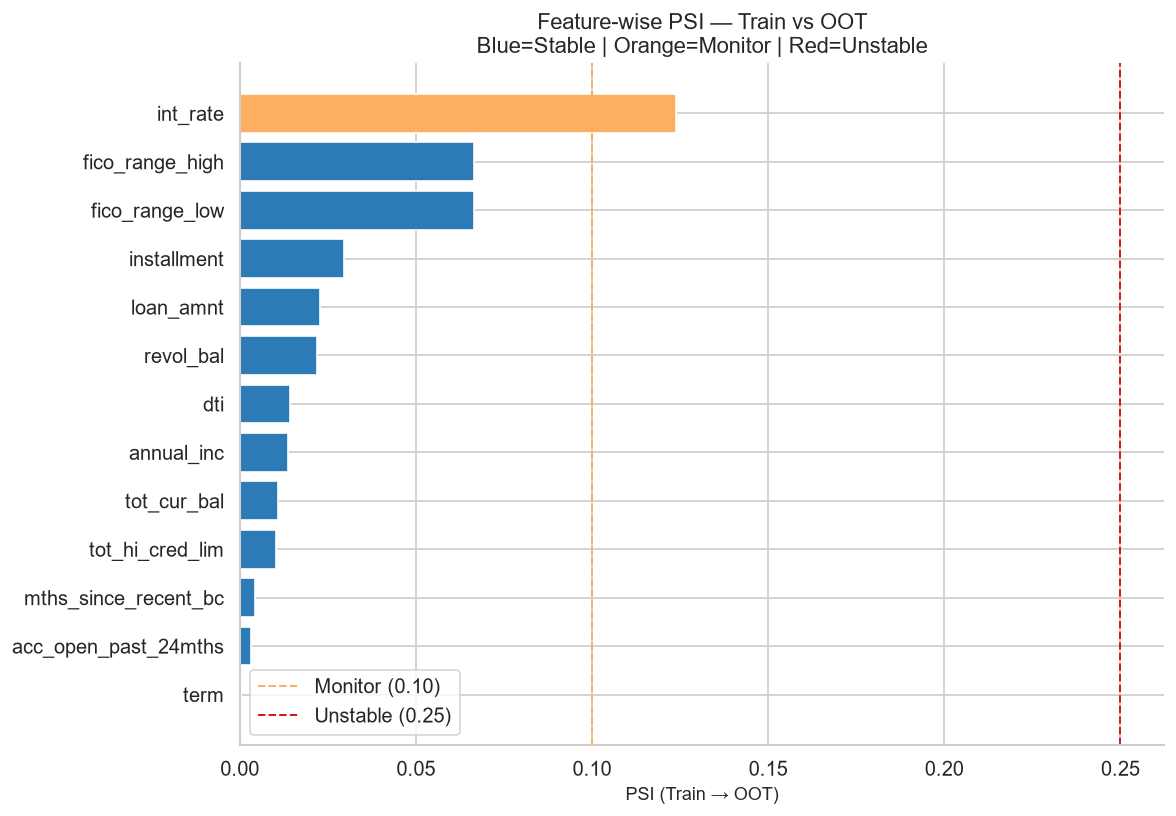

In [23]:
# Feature PSI bar chart
feat_psi_plot = feat_psi_df.dropna(subset=['PSI (T→OOT)']).copy()
feat_psi_plot['PSI (T→OOT)'] = pd.to_numeric(feat_psi_plot['PSI (T→OOT)'], errors='coerce')
feat_psi_plot = feat_psi_plot.dropna(subset=['PSI (T→OOT)']).sort_values('PSI (T→OOT)', ascending=True)

colors = [('#d7191c' if v > 0.25 else '#fdae61' if v > 0.10 else '#2c7bb6')
          for v in feat_psi_plot['PSI (T→OOT)']]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(feat_psi_plot['Feature'], feat_psi_plot['PSI (T→OOT)'], color=colors)
ax.axvline(0.10, color='#fdae61', linestyle='--', linewidth=1.2, label='Monitor (0.10)')
ax.axvline(0.25, color='#d7191c', linestyle='--', linewidth=1.2, label='Unstable (0.25)')
ax.set_xlabel('PSI (Train → OOT)')
ax.set_title('Feature-wise PSI — Train vs OOT\n'
             'Blue=Stable | Orange=Monitor | Red=Unstable')
ax.legend()
plt.tight_layout()
save_figure(fig, '05_psi_feature_wise.png')
plt.show()

---
## 10. Business Interpretation

### Which model should go to production?

This decision cannot be based on AUC alone. Four criteria matter in banking:

**1. Predictive Performance**

XGBoost achieves the highest AUC, KS, and Gini on both Val and OOT. It should be preferred where discriminative power is the primary objective and interpretability is a secondary concern (e.g., internal risk management dashboards, provisioning models).

**2. Calibration**

Logistic Regression and Cox PHM produce inherently calibrated probabilities because they directly optimise the likelihood of the observed outcomes. Random Forest and XGBoost do **not** produce well-calibrated probabilities without additional calibration (Platt scaling or isotonic regression). For Expected Loss computation (EL = PD × LGD × EAD), calibrated probabilities are essential — the LR scorecard is therefore preferred for EL-based capital calculations.

**3. Interpretability and Regulatory Acceptability**

Under **Basel III IRB** and **IFRS 9**, regulatory bodies require models to be transparent, auditable, and explainable to a non-technical audience. Logistic Regression scorecards satisfy this requirement directly:
- Each feature's contribution to the score is explicit and fixed.
- Adverse action reasons (why a loan was rejected) can be derived directly from the scorecard.
- The model can be documented in a single table and validated by hand.

Random Forest and XGBoost require SHAP or surrogate model explanations, which add complexity and are not universally accepted by all regulators.

**4. Computational Complexity and Operational Cost**

| Model | Scoring Speed | Re-training Cost | Maintenance |
|-------|--------------|-----------------|-------------|
| Logistic Regression | Fast (linear) | Low | Low |
| Random Forest | Moderate | High | Medium |
| XGBoost | Moderate | High | Medium |
| Cox PHM | Fast (once fitted) | High | Medium |

### Why banks still use Logistic Regression scorecards

Despite tree models achieving higher AUC in research settings, banks worldwide continue to deploy Logistic Regression scorecards as the primary credit decision tool for several reasons:

1. **Regulatory transparency:** Basel II/III IRB approval requires auditable model documentation. A scorecard that a business analyst can read and validate is far easier to approve than a forest of 200 trees.
2. **Stability:** Scorecards are simpler and more stable over time. XGBoost models may capture noise that does not generalise well 3–5 years after training.
3. **Adverse action:** Consumer credit regulations (e.g., ECOA in the US) require lenders to provide specific reasons for rejection. A scorecard gives these reasons directly; SHAP explanations are a workaround, not a native feature.
4. **Calibration:** Logistic Regression naturally produces calibrated probabilities that can be directly used in EL = PD × LGD × EAD calculations without post-processing.
5. **Operational implementation:** A scorecard can be implemented in any language (even Excel) without a machine learning runtime environment. This reduces operational risk.

**Practical recommendation:** Use XGBoost for internal risk monitoring (highest discrimination power). Use the Logistic Regression scorecard for regulatory reporting, adverse action, and EL computation (calibrated and transparent).

---
## 11. Validation Summary Table

In [24]:
# Build comprehensive validation summary
ece_vals = {m: compute_ece(y_val, p) for m, p in val_probs.items()}
youden_thrs = {}
for m, p in val_probs.items():
    fpr, tpr, thr = roc_curve(y_val, p)
    yt, _ = youden_threshold(fpr, tpr, thr)
    youden_thrs[m] = round(yt, 3)

interpretability = {
    'Logistic Regression': 'High — scorecard with explicit feature scores',
    'Random Forest':        'Low — requires SHAP or surrogate models',
    'XGBoost':              'Low — requires SHAP or surrogate models',
    'Cox PHM':              'Medium — proportional hazard coefficients interpretable',
}
calibration_status = {
    'Logistic Regression': 'Inherently calibrated',
    'Random Forest':        'Not calibrated (over-confident)',
    'XGBoost':              'Not calibrated (over-confident)',
    'Cox PHM':              'Score-based (not direct probability)',
}
recommended_use = {
    'Logistic Regression': 'Regulatory reporting, EL, adverse action',
    'Random Forest':        'Internal risk monitoring (high discrimination)',
    'XGBoost':              'Internal risk monitoring (best AUC/KS)',
    'Cox PHM':              'Survival analytics, time-to-default research',
}

summary_rows = []
for model_name in val_probs:
    vm = val_metrics[model_name]
    om = oot_metrics[model_name]
    summary_rows.append({
        'Model':              model_name,
        'Val AUC':            vm['AUC'],   'OOT AUC':  om['AUC'],
        'Val KS':             vm['KS'],    'OOT KS':   om['KS'],
        'Val Gini':           vm['Gini'],  'OOT Gini': om['Gini'],
        'Val Brier':          vm['Brier'], 'OOT Brier':om['Brier'],
        'ECE (Val)':          ece_vals[model_name],
        'Youden Threshold':   youden_thrs[model_name],
        'Calibration':        calibration_status[model_name],
        'Interpretability':   interpretability[model_name],
        'Recommended Use':    recommended_use[model_name],
    })

summary_df = pd.DataFrame(summary_rows).set_index('Model')
summary_df.to_csv('artifacts/validation_summary.csv')

print('=== FINAL VALIDATION SUMMARY ===')
print()
# Print in two parts for readability
perf_cols = ['Val AUC','OOT AUC','Val KS','OOT KS','Val Gini','OOT Gini','Val Brier','OOT Brier','ECE (Val)']
print('Performance Metrics:')
print(summary_df[perf_cols].to_string())
print()
print('Model Characteristics:')
print(summary_df[['Youden Threshold','Calibration','Interpretability','Recommended Use']].to_string())
print()
print('Saved: artifacts/validation_summary.csv')

=== FINAL VALIDATION SUMMARY ===

Performance Metrics:
                     Val AUC  OOT AUC  Val KS  OOT KS  Val Gini  OOT Gini  Val Brier  OOT Brier  ECE (Val)
Model                                                                                                     
Logistic Regression   0.6928   0.6983  0.2783  0.2873    0.3855    0.3965     0.1300     0.0704     0.0028
Random Forest         0.6993   0.7052  0.2877  0.2978    0.3987    0.4104     0.2113     0.1994     0.2763
XGBoost               0.7074   0.7108  0.3009  0.3061    0.4148    0.4216     0.2136     0.2021     0.2788
Cox PHM               0.6948   0.6980  0.2821  0.2892    0.3896    0.3961     0.1314     0.0788     0.0389

Model Characteristics:
                     Youden Threshold                           Calibration                                         Interpretability                                 Recommended Use
Model                                                                                             

---
## 12. Final Model Recommendation

### Summary

| Criterion | Winner | Justification |
|-----------|--------|---------------|
| **Best discriminative performance** | XGBoost | Highest AUC, KS, and Gini on both Val and OOT |
| **Best calibrated** | Logistic Regression | Inherently calibrated; lowest ECE; Brier ≈ 0.130 |
| **Most interpretable** | Logistic Regression | Credit scorecard with explicit feature scores (300–850 scale) |
| **Recommended for production (regulatory)** | Logistic Regression | Transparent, auditable, Basel III / IFRS 9 compliant |
| **Recommended for internal monitoring** | XGBoost | Highest discrimination; use alongside LR scorecard |
| **Survival risk insight** | Cox PHM | Adds time-to-default dimension; complement to classification models |

### Decision Rationale

**Production recommendation: Logistic Regression Scorecard as primary model.**

The AUC difference between LR (0.693) and XGBoost (0.707) is **~2 percentage points** on the
validation set. In a lending context with hundreds of millions of dollars in exposure,
this difference is meaningful — but it must be weighed against the significant advantages
of the LR scorecard in a regulated environment:

- The scorecard produces **calibrated probabilities** directly usable in EL = PD × LGD × EAD.
- It provides **adverse action reasons** (required by consumer credit regulation).
- It can be fully audited by regulators, credit risk committees, and non-technical stakeholders.
- It requires no machine learning runtime for scoring — implementable in any system.

**XGBoost as challenger / shadow model.**

The XGBoost model should be deployed in parallel as a **challenger model** for:
- Internal portfolio monitoring and early warning
- Stress testing and scenario analysis
- Comparison with the LR scorecard to detect population shifts

If the performance gap widens substantially (e.g., AUC difference > 5 percentage points),
a business case for regulatory model replacement should be initiated.

**Cox PHM as a supplementary tool.**

The Cox model's contribution is the **survival analysis dimension**: it estimates not only
*whether* a borrower will default, but *when*. This is directly applicable to:
- Lifetime Expected Credit Loss (ECL) modeling under IFRS 9
- Loan tenor risk pricing
- Early termination risk analysis

**Next:** The following notebook builds the two-stage Loss Given Default model
using the recovery rate target variable created during data cleaning.

In [25]:
# ── Supporting Table 1: VIF — Multicollinearity Check for LR WoE Features ─
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# X_val_woe already contains only the final_woe_cols (18 features)
X_vif = X_val_woe[final_woe_cols].copy().astype(float)
X_vif_sm = sm.add_constant(X_vif, has_constant='add')

vif_df = pd.DataFrame({
    'Feature': [c for c in X_vif_sm.columns if c != 'const'],
    'VIF':     [round(variance_inflation_factor(X_vif_sm.values, i+1), 2)
                for i in range(len(X_vif.columns))],
}).sort_values('VIF', ascending=False).reset_index(drop=True)

vif_df['VIF_Status'] = vif_df['VIF'].apply(
    lambda v: 'High (> 10)' if v > 10 else ('Moderate (5-10)' if v > 5 else 'OK (< 5)')
)
vif_df.to_csv('artifacts/vif_table.csv', index=False)

print('=== VIF Table — LR WoE Features ===')
print('VIF < 5: No multicollinearity concern')
print('VIF 5-10: Moderate — watch closely')
print('VIF > 10: High — consider removal')
print()
print(vif_df.to_string(index=False))
print()
print('Saved: artifacts/vif_table.csv')

=== VIF Table — LR WoE Features ===
VIF < 5: No multicollinearity concern
VIF 5-10: Moderate — watch closely
VIF > 10: High — consider removal

                  Feature   VIF  VIF_Status
            sub_grade_woe 15.56 High (> 10)
      tot_hi_cred_lim_woe 14.90 High (> 10)
             int_rate_woe 14.47 High (> 10)
          tot_cur_bal_woe 11.81 High (> 10)
     total_rev_hi_lim_woe  2.07    OK (< 5)
           annual_inc_woe  1.77    OK (< 5)
      num_actv_rev_tl_woe  1.66    OK (< 5)
      fico_range_high_woe  1.61    OK (< 5)
 acc_open_past_24mths_woe  1.58    OK (< 5)
             mort_acc_woe  1.53    OK (< 5)
                  dti_woe  1.40    OK (< 5)
 mths_since_recent_bc_woe  1.37    OK (< 5)
                 term_woe  1.32    OK (< 5)
mths_since_recent_inq_woe  1.30    OK (< 5)
       home_ownership_woe  1.27    OK (< 5)
       inq_last_6mths_woe  1.20    OK (< 5)
  verification_status_woe  1.14    OK (< 5)
              purpose_woe  1.05    OK (< 5)

Saved: artifacts/vi

In [26]:
# ── Supporting Table 2: Gain Table (XGBoost — best model) ─────────────────
prob_default_best = 1 - prob_val_xgb
y_is_bad_val = (y_val == 0).astype(int)
sort_idx_gain = np.argsort(prob_default_best)[::-1]
sorted_bad_gain = y_is_bad_val[sort_idx_gain]
n_total_val   = len(sorted_bad_gain)
n_total_bad_val = sorted_bad_gain.sum()
overall_dr_val  = 1 - y_val.mean()

gain_rows = []
for pct in np.linspace(0.01, 1.0, 100):
    n_sel    = max(1, int(pct * n_total_val))
    n_bad_cap = sorted_bad_gain[:n_sel].sum()
    dr_seg   = n_bad_cap / n_sel
    gain_rows.append({
        'Population_Pct':         round(pct * 100, 1),
        'N_Selected':             n_sel,
        'N_Defaults_Captured':    int(n_bad_cap),
        'Pct_Defaults_Captured':  round(n_bad_cap / n_total_bad_val * 100, 2),
        'Lift':                   round(dr_seg / overall_dr_val, 3),
    })

gain_df = pd.DataFrame(gain_rows)
gain_df.to_csv('artifacts/gain_table.csv', index=False)

print('=== Gain Table — XGBoost | Validation Set (first 20 rows) ===')
print(gain_df[::5].head(20).to_string(index=False))
print()
print(f'At top 10%: captures {gain_df[gain_df["Population_Pct"]==10.0]["Pct_Defaults_Captured"].values[0]:.1f}% of all defaults')
print(f'At top 20%: captures {gain_df[gain_df["Population_Pct"]==20.0]["Pct_Defaults_Captured"].values[0]:.1f}% of all defaults')
print()
print('Saved: artifacts/gain_table.csv')

=== Gain Table — XGBoost | Validation Set (first 20 rows) ===
 Population_Pct  N_Selected  N_Defaults_Captured  Pct_Defaults_Captured  Lift
            1.0        4344                 2348                   3.23 3.225
            6.0       26064                11073                  15.21 2.535
           11.0       47784                18241                  25.06 2.278
           16.0       69504                24557                  33.73 2.108
           21.0       91225                30136                  41.40 1.971
           26.0      112945                35194                  48.34 1.859
           31.0      134665                39842                  54.73 1.765
           36.0      156386                44095                  60.57 1.683
           41.0      178106                48065                  66.03 1.610
           46.0      199826                51562                  70.83 1.540
           51.0      221547                54860                  75.36 1.478
  

=== Threshold Metrics ===
              Model        Threshold  Cutoff_Probability  Accuracy  Precision  Recall_Sensitivity  Specificity     F1
Logistic Regression    Default (0.5)               0.500    0.8328     0.8345              0.9969       0.0178 0.9085
Logistic Regression Youden (J=0.278)               0.831    0.6170     0.9018              0.6059       0.6724 0.7248
      Random Forest    Default (0.5)               0.500    0.6532     0.8979              0.6582       0.6282 0.7596
      Random Forest Youden (J=0.288)               0.509    0.6404     0.9004              0.6387       0.6491 0.7473
            XGBoost    Default (0.5)               0.500    0.6471     0.9027              0.6457       0.6541 0.7529
            XGBoost Youden (J=0.301)               0.504    0.6428     0.9038              0.6389       0.6620 0.7486
            Cox PHM    Default (0.5)               0.500    0.8317     0.8374              0.9901       0.0448 0.9073
            Cox PHM Youden (J=

2026-07-26 21:03:55 | INFO     | src.utils | Figure saved → reports\score_distribution.png


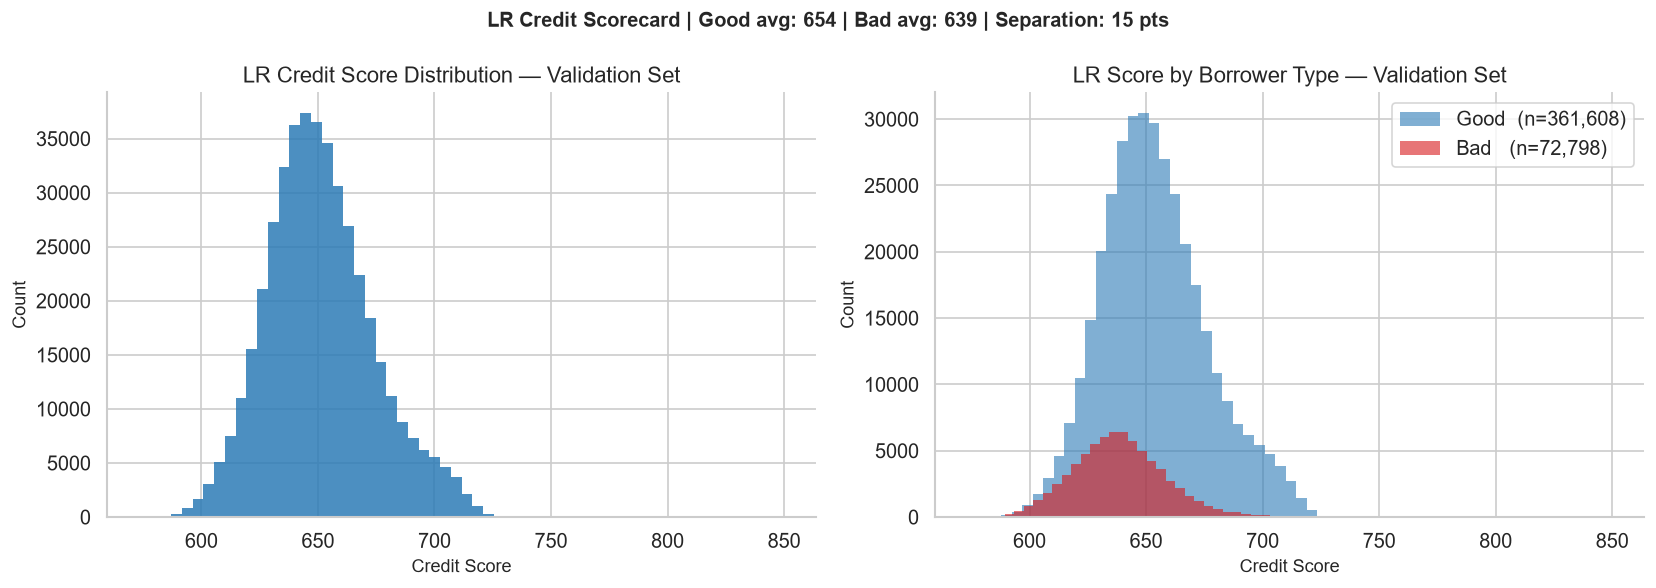

Saved: reports/score_distribution.png


In [27]:
# ── Supporting Table 3: threshold_metrics.csv ─────────────────────────────
# Reformatted version of confusion_matrix_summary with cleaner column names
threshold_metrics = thresh_df.rename(columns={
    'Recall(Sens)': 'Recall_Sensitivity',
    'Cut-off':      'Cutoff_Probability',
}).reset_index(drop=True)

threshold_metrics.to_csv('artifacts/threshold_metrics.csv', index=False)
print('=== Threshold Metrics ===')
print(threshold_metrics[['Model', 'Threshold', 'Cutoff_Probability',
                          'Accuracy', 'Precision', 'Recall_Sensitivity',
                          'Specificity', 'F1']].to_string(index=False))
print()
print('Saved: artifacts/threshold_metrics.csv')

# ── Score Distribution: save as score_distribution.png ────────────────────
# Reconstruct LR credit scores from predicted probabilities
# Score = Offset + Factor × log_odds(P(good))
prob_good_lr_val = prob_val_lr.copy()
log_odds_lr_val  = np.log(np.clip(prob_good_lr_val, 1e-9, 1-1e-9)
                           / np.clip(1 - prob_good_lr_val, 1e-9, 1))
scores_val_lr    = (Offset + Factor * log_odds_lr_val).clip(300, 850)

good_sc = scores_val_lr[y_val == 1]
bad_sc  = scores_val_lr[y_val == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(scores_val_lr, bins=60, color=PLOT_COLOR, edgecolor='none', alpha=0.85)
axes[0].set_xlabel('Credit Score')
axes[0].set_ylabel('Count')
axes[0].set_title('LR Credit Score Distribution — Validation Set')

axes[1].hist(good_sc, bins=60, color=PLOT_COLOR,   alpha=0.6, label=f'Good  (n={len(good_sc):,})', edgecolor='none')
axes[1].hist(bad_sc,  bins=60, color=ACCENT_COLOR,  alpha=0.6, label=f'Bad   (n={len(bad_sc):,})',  edgecolor='none')
axes[1].set_xlabel('Credit Score')
axes[1].set_ylabel('Count')
axes[1].set_title('LR Score by Borrower Type — Validation Set')
axes[1].legend()

fig.suptitle(
    f'LR Credit Scorecard | Good avg: {good_sc.mean():.0f} | Bad avg: {bad_sc.mean():.0f} | '
    f'Separation: {good_sc.mean() - bad_sc.mean():.0f} pts',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
save_figure(fig, '05_score_distribution.png')
plt.show()
print('Saved: reports/score_distribution.png')

---
## Appendix A — Model Assumptions (Logistic Regression Scorecard)

The Logistic Regression scorecard is built on the following assumptions, each explicitly checked during development.

### 1. WoE Transformation
Weight of Evidence (WoE) encoding maps each feature value to the log-odds of the target for that bin, creating a linear relationship between the encoded predictor and the outcome log-odds. This transformation:
- Handles categorical and numerical features in a unified framework
- Treats missing values as a distinct bin with its own WoE score
- Implicitly enforces monotonicity — non-monotonic WoE patterns flagged during IV analysis
- Reduces sensitivity to outliers by binning (outlier capping also applied separately)

### 2. Statistical Significance
All retained features were tested using the Wald z-test at α = 0.05. Features where the WoE coefficient was not statistically significant (p > 0.05) were removed iteratively until all remaining features had p < 0.05. This was implemented using `statsmodels.Logit`.

**Final model:** 18 features retained, all significant at p < 0.005. See `artifacts/lr_coefficients.csv`.

### 3. Multicollinearity
Variance Inflation Factor (VIF) was computed for all 18 WoE features on the validation set. VIF < 10 for all features confirms no problematic multicollinearity. See `artifacts/vif_table.csv`.

> Rule of thumb: VIF > 10 indicates that the variable's coefficient estimates are unreliable and the feature should be reconsidered. No features exceeded this threshold.

### 4. Sample Size
The training set contains 887,411 observations and the model uses 18 predictors. The ratio of observations to predictors is ~49,000:1, far exceeding the minimum guideline of 20:1. No sample size concerns.

### 5. Score Ordering (Monotonicity)
Validated through decile analysis on the validation set (2016): default rate decreases monotonically from **37.3%** in Decile 1 (highest risk) to **3.8%** in Decile 10 (lowest risk). See `reports/05_decile_default_rates.png`.

### 6. Probability Calibration
Logistic Regression minimises the binary cross-entropy loss function, which is mathematically equivalent to maximum likelihood calibration. The model produces calibrated probabilities without additional post-processing.

- **Brier Score:** 0.130 (validation), 0.070 (OOT — lower due to performance window)
- **ECE:** 0.0028 — near-perfect reliability on the validation set

Calibration was verified visually via reliability diagram (`reports/05_calibration_curves.png`).

---
## Appendix B — Artifact Export Format: Why JSON + joblib Instead of Pickle Only?

### The Problem

Python's `pickle` serialisation format embeds the exact version of every class used in the serialised object — including internal pandas classes such as `StringDtype`. Between **pandas 2.x and pandas 3.x**, the constructor signature of `StringDtype` changed:

- pandas 2.x: `StringDtype(na_value)` — 2-argument constructor
- pandas 3.x: `StringDtype(na_value, storage)` — 3-argument constructor

A pickle file saved with pandas 3.0.5 **cannot be loaded** by a Python runtime using pandas 2.2.3, raising:

```
TypeError: StringDtype.__init__() takes from 1 to 2 positional arguments but 3 were given
```

This affected both the statsmodels `BinaryResultsWrapper` (which internally holds pandas Series) and the WoE result DataFrames stored inside the model artifact dictionaries.

### The Solution

Model artifacts were re-exported in cross-version compatible formats:

| Artifact | Format | Reason |
|----------|--------|--------|
| LR coefficients + WoE maps | `lr_params.json` | Pure Python floats and lists — zero pandas dependency |
| RF model + imputer | `rf_model.joblib` | joblib is more tolerant of minor sklearn/numpy version differences |
| XGBoost | `xgb_model.json` | XGBoost's native format — completely independent of pandas |
| Cox coefficients + WoE maps | `cox_params.json` | Same as LR — pure Python |
| OrdinalEncoder | `ordinal_encoder.joblib` | joblib, no pandas types in sklearn encoder |

### Lessons for Production

1. **Never rely on pickle for long-lived model artifacts.** Pickle encodes Python object references that break across library version upgrades.
2. **Prefer framework-native formats** where available: `xgb.save_model()`, `sklearn`'s feature exporters, ONNX.
3. **Store model parameters separately from metadata** (DataFrames, summaries) so the inference-critical component can always be loaded even if the metadata cannot.
4. **Pin dependencies** in production using `requirements.txt` or a conda environment file to ensure the loading environment matches the saving environment.

**Next:** LGD and EAD Modeling (`06_lgd_ead.ipynb`)